# Airline Passenger Satisfaction – Random Forest Classifier
**Goal:** predict whether a passenger is *Satisfied* or *Neutral/Dissatisfied* from trip details and service ratings, then explain predictions with SHAP and deploy the model on a website.

**Dataset:** 129,880 passengers, 22 input features, 1 binary target (`Satisfaction`).
**Method:** scikit-learn `Pipeline` (preprocessing + Random Forest), evaluated with a held-out test set and 5-fold cross-validation.

In [ ]:
!pip install scikit-learn==1.9.1

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 20.2 MB/s  0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1


In [ ]:
import sklearn
print(sklearn.__version__)

1.9.1


In [ ]:

import json, sys
import joblib, shap, sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay)
RANDOM_STATE = 42

## 1. Load and inspect the data

In [ ]:
df = pd.read_csv("airline_passenger_satisfaction.csv")
print("Shape:", df.shape)
print("Duplicate rows (ignoring ID):", df.drop(columns=["ID"]).duplicated().sum())
df.head()

Shape: (129880, 24)
Duplicate rows (ignoring ID): 0


,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,Male,48,First-time,Business,Business,821,2,5.0,3,...,3,5,2,5,5,5,3,5,5,Neutral or Dissatisfied
1,2,Female,35,Returning,Business,Business,821,26,39.0,2,...,5,4,5,5,3,5,2,5,5,Satisfied
2,3,Male,41,Returning,Business,Business,853,0,0.0,4,...,3,5,3,5,5,3,4,3,3,Satisfied
3,4,Male,50,Returning,Business,Business,1905,0,0.0,2,...,5,5,5,4,4,5,2,5,5,Satisfied
4,5,Female,49,Returning,Business,Business,3470,0,1.0,3,...,3,4,4,5,4,3,3,3,3,Satisfied


In [ ]:
print("Missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])
df.describe().T

Missing values:
Arrival Delay    393
dtype: int64


,count,mean,std,min,25%,50%,75%,max
ID,129880.0,64940.500000,37493.270818,1.0,32470.75,64940.5,97410.25,129880.0
Age,129880.0,39.427957,15.119360,7.0,27.00,40.0,51.00,85.0
Flight Distance,129880.0,1190.316392,997.452477,31.0,414.00,844.0,1744.00,4983.0
Departure Delay,129880.0,14.713713,38.071126,0.0,0.00,0.0,12.00,1592.0
Arrival Delay,129487.0,15.091129,38.465650,0.0,0.00,0.0,13.00,1584.0
Departure and Arrival Time Convenience,129880.0,3.057599,1.526741,0.0,2.00,3.0,4.00,5.0
Ease of Online Booking,129880.0,2.756876,1.401740,0.0,2.00,3.0,4.00,5.0
Check-in Service,129880.0,3.306267,1.266185,0.0,3.00,3.0,4.00,5.0
Online Boarding,129880.0,3.252633,1.350719,0.0,2.00,3.0,4.00,5.0
Gate Location,129880.0,2.976925,1.278520,0.0,2.00,3.0,4.00,5.0


### Class balance
The classes are reasonably balanced (about 57% / 43%)

Satisfaction
Neutral or Dissatisfied    0.566
Satisfied                  0.434
Name: count, dtype: float64


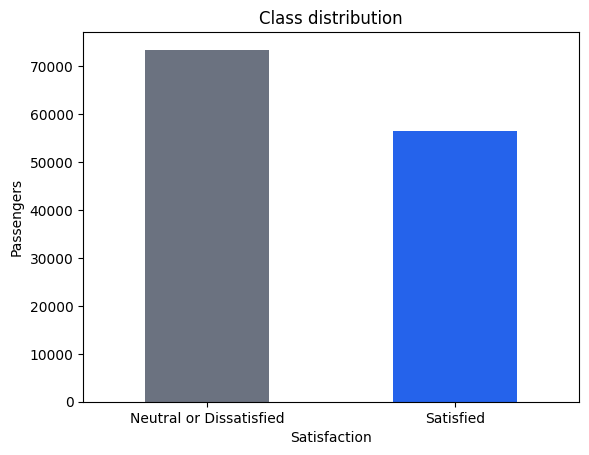

In [ ]:
counts = df["Satisfaction"].value_counts()
print((counts / len(df)).round(3))
counts.plot(kind="bar", color=["#6b7280", "#2563eb"], rot=0, title="Class distribution")
plt.ylabel("Passengers"); plt.show()

In [ ]:
rating_cols = [c for c in df.columns if c not in
               ["ID","Gender","Age","Customer Type","Type of Travel","Class",
                "Flight Distance","Departure Delay","Arrival Delay","Satisfaction"]]
print("Share of 0 ratings per column:")
print((df[rating_cols] == 0).mean().round(3).sort_values(ascending=False))

Share of 0 ratings per column:
Departure and Arrival Time Convenience    0.051
Ease of Online Booking                    0.044
In-flight Wifi Service                    0.030
Online Boarding                           0.024
Leg Room Service                          0.005
Food and Drink                            0.001
On-board Service                          0.000
Gate Location                             0.000
Check-in Service                          0.000
Seat Comfort                              0.000
Cleanliness                               0.000
In-flight Service                         0.000
In-flight Entertainment                   0.000
Baggage Handling                          0.000
dtype: float64


## 2. Prepare features and target


In [ ]:
df = df.drop(columns=["ID"])
y = (df["Satisfaction"] == "Satisfied").astype(int)      # 1 = Satisfied, 0 = Neutral/Dissatisfied
X = df.drop(columns=["Satisfaction"])

assert "ID" not in X.columns and "Satisfaction" not in X.columns
categorical = ["Gender", "Customer Type", "Type of Travel", "Class"]
numeric = [c for c in X.columns if c not in categorical]
print(len(X.columns), "input features")
print(list(X.columns))

22 input features
['Gender', 'Age', 'Customer Type', 'Type of Travel', 'Class', 'Flight Distance', 'Departure Delay', 'Arrival Delay', 'Departure and Arrival Time Convenience', 'Ease of Online Booking', 'Check-in Service', 'Online Boarding', 'Gate Location', 'On-board Service', 'Seat Comfort', 'Leg Room Service', 'Cleanliness', 'Food and Drink', 'In-flight Service', 'In-flight Wifi Service', 'In-flight Entertainment', 'Baggage Handling']


## 3. Pipeline and model training


In [ ]:
preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
    ("num", SimpleImputer(strategy="median"), numeric),
])

model = Pipeline([
    ("prep", preprocess),
    ("clf", RandomForestClassifier(n_estimators=150, max_depth=20, min_samples_leaf=3,
                                   random_state=RANDOM_STATE, n_jobs=-1)),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

model.fit(X_train, y_train)

Train: (103904, 22)  Test: (25976, 22)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](22,)","['Gender','Age','Customer Type',...,'In-flight Wifi Service', 'In-flight Entertainment','Baggage Handling']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,22
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remai

## 4. Evaluation

In [ ]:
pred = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]
print(f"Test accuracy : {accuracy_score(y_test, pred):.4f}")
print(f"Train accuracy: {accuracy_score(y_train, model.predict(X_train)):.4f}")
print(f"ROC-AUC       : {roc_auc_score(y_test, proba):.4f}\n")
print(classification_report(y_test, pred, target_names=["Neutral/Dissatisfied", "Satisfied"], digits=3))

Test accuracy : 0.9633
Train accuracy: 0.9794
ROC-AUC       : 0.9942

                      precision    recall  f1-score   support

Neutral/Dissatisfied      0.958     0.978     0.968     14690
           Satisfied      0.971     0.944     0.957     11286

            accuracy                          0.963     25976
           macro avg      0.964     0.961     0.963     25976
        weighted avg      0.963     0.963     0.963     25976



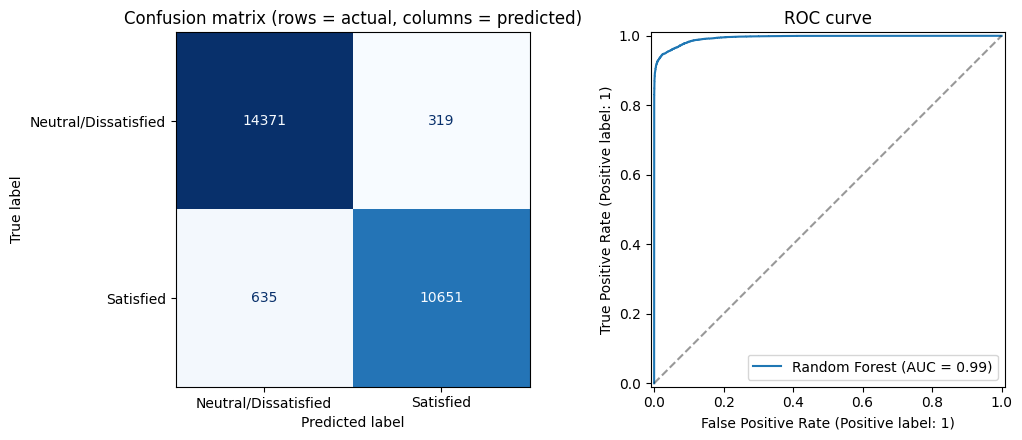

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=["Neutral/Dissatisfied", "Satisfied"],
    cmap="Blues", ax=ax[0], colorbar=False)
ax[0].set_title("Confusion matrix (rows = actual, columns = predicted)")
RocCurveDisplay.from_predictions(y_test, proba, ax=ax[1], name="Random Forest")
ax[1].plot([0, 1], [0, 1], "k--", alpha=.4); ax[1].set_title("ROC curve")
plt.tight_layout(); plt.show()

### 5-fold cross-validation (shuffled)


In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy", n_jobs=1)
print("Accuracy per fold:", cv_scores.round(4))
print(f"Mean: {cv_scores.mean():.4f}   Std: {cv_scores.std():.4f}")

Accuracy per fold: [0.9634 0.9608 0.9638 0.962  0.9627]
Mean: 0.9625   Std: 0.0011


## 5. Feature importance and SHAP explanations


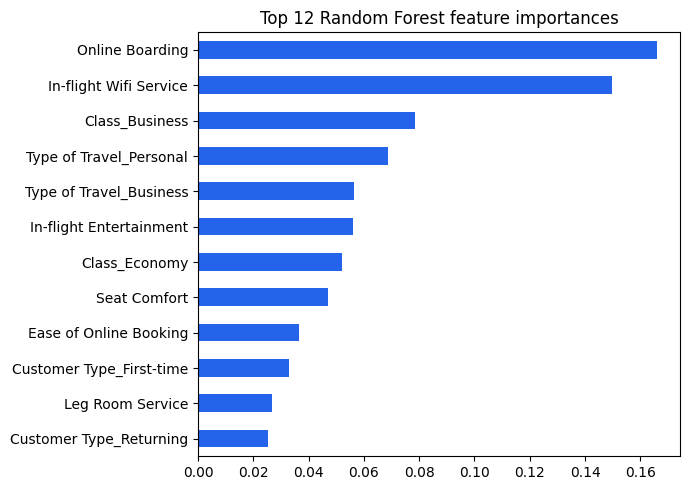

In [ ]:
prep = model.named_steps["prep"]
rf = model.named_steps["clf"]
feature_names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]

imp = pd.Series(rf.feature_importances_, index=feature_names).sort_values().tail(12)
imp.plot(kind="barh", figsize=(7, 5), color="#2563eb", title="Top 12 Random Forest feature importances")
plt.tight_layout(); plt.show()

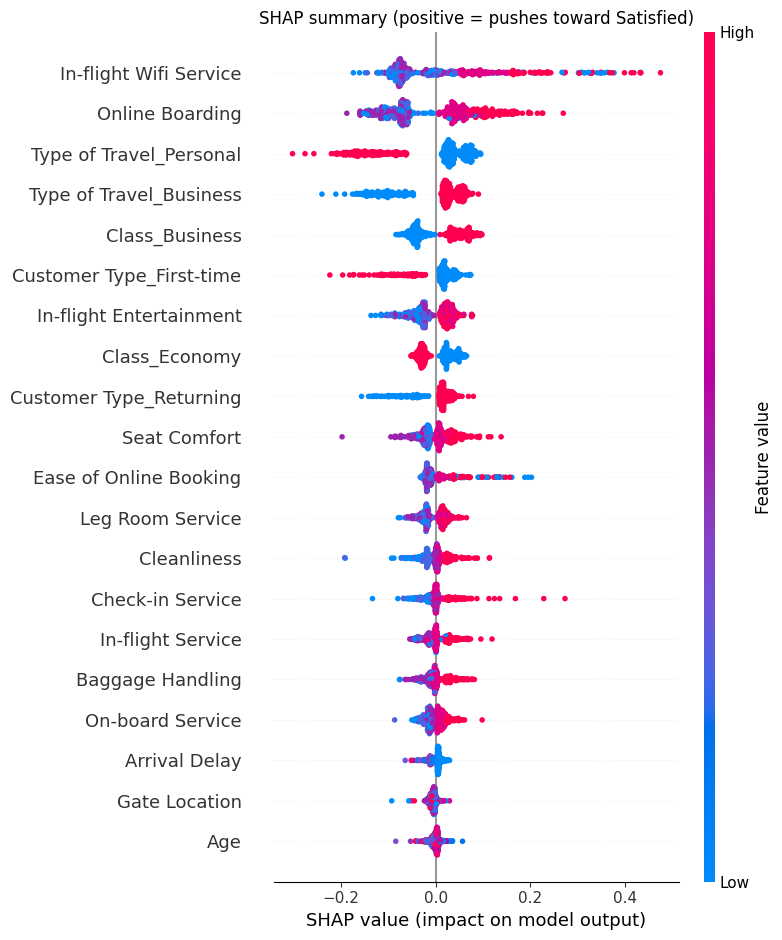

In [ ]:
explainer = shap.TreeExplainer(rf)
X_sample = X_test.sample(500, random_state=RANDOM_STATE)
X_sample_t = prep.transform(X_sample)
if hasattr(X_sample_t, "toarray"):
    X_sample_t = X_sample_t.toarray()
X_sample_df = pd.DataFrame(X_sample_t, columns=feature_names)

sv_all = explainer(X_sample_df).values
sv = sv_all[:, :, 1] if sv_all.ndim == 3 else sv_all
base_value = float(np.ravel(explainer.expected_value)[-1])

shap.summary_plot(sv, X_sample_df, show=False)
plt.title("SHAP summary (positive = pushes toward Satisfied)"); plt.tight_layout(); plt.show()

Predicted class: Satisfied
P(Satisfied) = 100.0%  (average passenger: 43.4%)


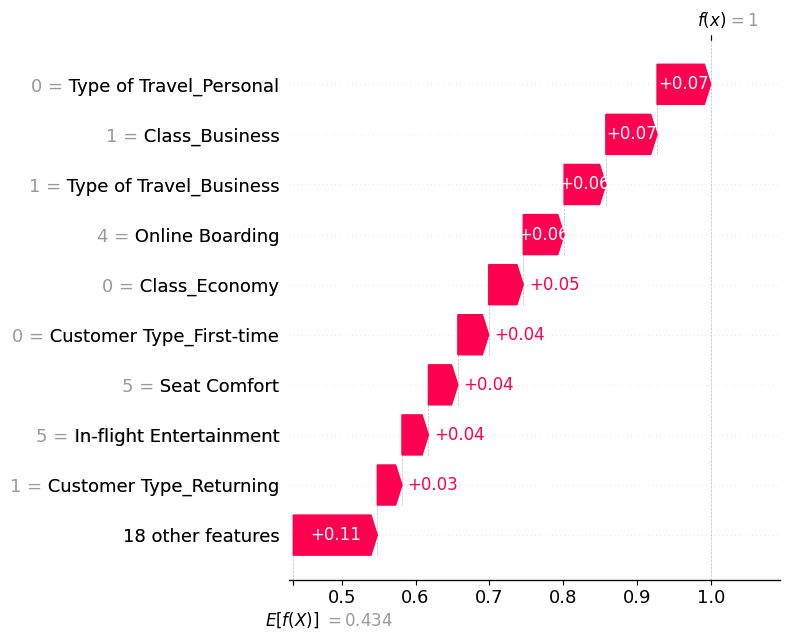

In [ ]:
i = 0
print("Predicted class:", "Satisfied" if model.predict(X_sample.iloc[[i]])[0] == 1 else "Neutral/Dissatisfied")
print(f"P(Satisfied) = {model.predict_proba(X_sample.iloc[[i]])[0, 1]:.1%}  (average passenger: {base_value:.1%})")
exp = shap.Explanation(values=sv[i], base_values=base_value,
                       data=X_sample_df.iloc[i].values, feature_names=feature_names)
shap.plots.waterfall(exp, show=False)
plt.tight_layout(); plt.show()

## 6. Save everything the website needs


In [ ]:
joblib.dump(model, "airline_model_pipeline.pkl", compress=3)
joblib.dump(list(X.columns), "feature_names.pkl")

model_info = {
    "categorical_options": {c: sorted(X[c].unique().tolist()) for c in categorical},
    "numeric_ranges": {c: [float(X[c].min()), float(X[c].max())] for c in numeric},
    "rating_columns": rating_cols,
    "target_mapping": {"0": "Neutral or Dissatisfied", "1": "Satisfied"},
    "metrics": {"test_accuracy": round(float(accuracy_score(y_test, pred)), 4),
                "cv_accuracy_mean": round(float(cv_scores.mean()), 4),
                "roc_auc": round(float(roc_auc_score(y_test, proba)), 4)},
    "versions": {"python": sys.version.split()[0], "scikit_learn": sklearn.__version__,
                 "pandas": pd.__version__, "numpy": np.__version__, "shap": shap.__version__},
}
with open("model_info.json", "w") as f:
    json.dump(model_info, f, indent=2)
print("Saved: airline_model_pipeline.pkl, feature_names.pkl, model_info.json")
print(json.dumps(model_info["versions"], indent=2))

Saved: airline_model_pipeline.pkl, feature_names.pkl, model_info.json
{
  "python": "3.13.18",
  "scikit_learn": "1.9.1",
  "pandas": "2.2.3",
  "numpy": "2.4.6",
  "shap": "0.54.1"
}


### Sanity check: reload the saved files and predict one new passenger

In [ ]:
loaded = joblib.load("airline_model_pipeline.pkl")
cols = joblib.load("feature_names.pkl")
new_passenger = {
    "Gender": "Female", "Age": 35, "Customer Type": "Returning", "Type of Travel": "Business",
    "Class": "Business", "Flight Distance": 1200, "Departure Delay": 0, "Arrival Delay": 0,
    "Departure and Arrival Time Convenience": 4, "Ease of Online Booking": 4, "Check-in Service": 4,
    "Online Boarding": 5, "Gate Location": 3, "On-board Service": 4, "Seat Comfort": 5,
    "Leg Room Service": 4, "Cleanliness": 4, "Food and Drink": 4, "In-flight Service": 4,
    "In-flight Wifi Service": 4, "In-flight Entertainment": 5, "Baggage Handling": 4,
}
row = pd.DataFrame([new_passenger])[cols]
print("Prediction:", "Satisfied" if loaded.predict(row)[0] == 1 else "Neutral/Dissatisfied")
print(f"P(Satisfied): {loaded.predict_proba(row)[0, 1]:.1%}")

Prediction: Satisfied
P(Satisfied): 85.5%


## 7. Limitations
- **What the model really does:** satisfaction is measured by a survey *after* the flight, and many inputs (wifi, boarding, seat comfort) are themselves satisfaction ratings. The model classifies overall satisfaction from component ratings; it does not forecast satisfaction before the flight.
- **Feature importance and SHAP are associations, not causes.**
- **Sensitive attributes** (Gender, Age) are inputs. Their importance is low, but a production system should review fairness.
- **Single dataset:** results may not transfer to other airlines or regions.
- **Not validated on live data:** accuracy should be re-checked if the data distribution changes.